In [1]:
import functions as AvT
import xarray as xr
import numpy as np
import mne
from datetime import datetime
import os
import math
import pickle

1. Collecting data

In [2]:
#parameters
ds_name = "labelled_data_200hz_t2.nc"       #file name for the dataset
info_fname = "S1_epo.fif"                   #file name for the metadata
condition = None                            #condition

#create dataset
ds = xr.open_dataset(f"data/{ds_name}")
if condition != None: ds = ds.where(ds["condition"] == condition, drop=True)
print(ds.attrs)

#create eeg/probabilities arrays
probs = ds.probabilities.values
eeg = ds.data.values

#info object
info = mne.io.read_info(f"data/{info_fname}")
old_info = info.copy()

info = mne.create_info(
    ch_names=ds.channel.values.tolist(),
    sfreq=ds.attrs["sfreq"],
    ch_types="eeg",
)
with info._unlock():
    info["lowpass"] = float(ds.attrs["lowpass"])
    info["highpass"] = float(ds.attrs["highpass"])

montage = old_info.get_montage()
if montage is not None: info.set_montage(montage)

#delete irrelevant variables to save memory
del ds

{'sfreq': 200.0, 'offset': 10, 'offset_before': 50, 'lowpass': 50.0, 'highpass': 1.0, 'lower_limit_rt': 0.2, 'upper_limit_rt': inf, 'reject_threshold': 0.0001, 'n_trials': 23235, 'extra_offset': 50, 'task': 'prp1/t2'}


2. Preparing epochs

In [3]:
offset = 40
n_participants = 30
n_batchsize = 500

#filter valid trials
if n_participants > eeg.shape[0]:
    n_participants = eeg.shape[0]
    print(f"The dataset does not contain sufficient participants for your request, so we changed the number of participants to {n_participants}")

valid_trials = ~np.isnan(eeg[:n_participants, :, :, 0]).any(axis=2)

#extract centers from event probabilities
centers = []
valid_probs = probs[valid_trials]

for n_event in range(valid_probs.shape[1]):
    trial_centers = []

    #add the centred data for every trail using context
    for trial in range(valid_probs.shape[0]):              
        center = int(np.argmax(valid_probs[trial, n_event, :])) - 1
        if center > 0: trial_centers.append(center)

    center = np.average(trial_centers)
    if not np.isnan(center): 
        center = round(center)
        centers.append(center)


#create batches
participant_batches = []
for participant in range(n_participants):
    participant_eeg = eeg[participant][valid_trials[participant]]
    participant_probs = probs[participant][valid_trials[participant]]
    n_trials = participant_eeg.shape[0]

    eeg_batches = []
    for n in range(math.ceil(n_trials/n_batchsize)):
        lower = n_batchsize*n
        if n_batchsize*(n+1) <= n_trials: upper = n_batchsize*(n+1)
        else: upper = -1

        eeg_batches.append((participant_eeg[lower:upper], participant_probs[lower:upper]))

    participant_batches.append(eeg_batches)

#create epochs
for n, participant_batch in enumerate(participant_batches):
    epochs_batches = []
    for eeg_batch, probs_batch in participant_batch: epochs_batches.append((mne.EpochsArray(np.nan_to_num(eeg_batch, nan=0.0), info, tmin=-offset/info['sfreq']), probs_batch))
    participant_batches[n] = epochs_batches

#delete irrelevant variables to save memory
del valid_probs
del eeg
del probs

The dataset does not contain sufficient participants for your request, so we changed the number of participants to 21


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\numpy\lib\function_base.py:520: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
311 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
195 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
161 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
299 matching eve

3. Generating events

In [6]:
#parameters
n_jobs = 1                                                              #parallel processes
baseline = (None, -0.15)                                                #TFR baseline       
steps = 30                                                              #n_steps within the frequency interval

low_freq = 2                                                            #lower bound frequency interval
high_freq = 40                                                          #higher bound frequency interval

low_cycle = 1                                                           #lower bound n_cycle interval
high_cycle = 6                                                          #higher bound n_cycle interval

labels = ['null', 'encoding', 'central', 'response']

freqs = list(np.logspace(np.log10(low_freq), np.log10(high_freq), steps))
n_cycles = list(np.logspace(np.log10(low_cycle), np.log10(high_cycle), steps))

directory_name = f"{ds_name} condition={condition} n_participants={n_participants} baseline={baseline} steps={steps} cycles=({low_cycle}, {high_cycle}) {datetime.today().strftime('%Y-%m-%d')}"
if not os.path.exists(f"output/{directory_name}"): os.mkdir(f"output/{directory_name}")

3.1 Generating TFR events

In [ ]:
#create folder for TFRs
if not os.path.exists(f"output/{directory_name}/tfr"): os.mkdir(f"output/{directory_name}/tfr")

#create TFRs for every participant
for n_participant, participant_batch in enumerate(participant_batches):
    print(f"participant: {n_participant+1}/{len(participant_batches)}")
    n_participant_trials = np.sum([participant_batch[x][0]._data.shape[0] for x in range(len(participant_batch))])

    #create participant folder
    if not os.path.exists(f"output/{directory_name}/tfr/S{n_participant+1}"): os.mkdir(f"output/{directory_name}/tfr/S{n_participant+1}")

    #per epoch batch create a TFR and TFR events
    for n_batch, (epochs_batch, probs_batch) in enumerate(participant_batch):
        print(f"batch: {n_batch+1}/{len(participant_batch)}")
        batch_ratio = len(epochs_batch)/n_participant_trials

        if n_batch == 0:
            #create TFR and TFR events
            tfr = AvT.get_tfr(epochs_batch, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
            tfr_events = AvT.get_events(tfr._data, probs_batch, freqs, info, labels, instance='tfr', cycles=n_cycles, jobs=n_jobs)
            tfr = tfr.average()
            tfr._data[tfr._data == -np.inf] = np.nan

            #multiply batch with it ratio to all trials
            tfr._data *= batch_ratio
            for tfr_event in tfr_events: tfr_event[0]._data *= batch_ratio
            
        else:
            #create TFR and TFR events
            temp_tfr = AvT.get_tfr(epochs_batch, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
            temp_tfr_events = AvT.get_events(temp_tfr._data, probs_batch, freqs, info, labels, instance='tfr', cycles=n_cycles, jobs=n_jobs)
            temp_tfr = temp_tfr.average()
            temp_tfr._data[temp_tfr._data == -np.inf] = np.nan  

            #add TFR and TFR events to current instances
            for n, temp_tfr_event in enumerate(temp_tfr_events):
                temp_tfr_event[0]._data *= batch_ratio
                tfr_events[n].__add__(temp_tfr_event)
                
            temp_tfr *= batch_ratio
            tfr.__add__(temp_tfr)

            #delete temporary TFRs to save memory
            del temp_tfr
            del temp_tfr_events

    #saving TFRs to the disk
    print("Saving participant")
    tfr.save(f"output/{directory_name}/tfr/S{n_participant+1}/total_tfr.hdf5", overwrite=True)
    for tfr_event in tfr_events: tfr_event[0].save(f"output/{directory_name}/tfr/S{n_participant+1}/{tfr_event[1]}_tfr.hdf5", overwrite=True)

    #delete irrelevant variables to save memory
    del tfr
    del tfr_events
    del participant_batch

#combine results and save to disk
print("Combining files")
tfr_dict_combined = AvT.combine_participants(directory_name, instance='tfr', combine=True)
tfr_dict_individual = AvT.combine_participants(directory_name, instance='tfr', combine=False)
with open(f"output/{directory_name}/tfr/tfr_dict_combined.pkl", 'wb') as file: pickle.dump(tfr_dict_combined, file)
with open(f"output/{directory_name}/tfr/tfr_dict_individual.pkl", 'wb') as file: pickle.dump(tfr_dict_individual, file)
del tfr_dict_combined
del tfr_dict_individual

participant: 1/21
batch: 1/2
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 2/2
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


Saving participant
participant: 2/21
batch: 1/3
Applying baseline correction (mode: logratio)


...

C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 3/3
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


Saving participant
Combining files
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz_t2.nc condition=None n_participants=21 baseline=(None, -0.15) steps=30 cycles=(1, 6) 2026-10-08\tfr\S1\1_encoding_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz_t2.nc condition=None n_participants=21 baseline=(None, -0.15) steps=30 cycles=(1, 6) 2026-10-08\tfr\S1\2_central_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz_t2.nc condition=None n_participants=21 baseline=(None, -0.15) steps=30 cycles=(1, 6) 2026-10-08\tfr\S1\3_response_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz_t2.nc condition=None n_participants=21 baseline=(None, -0.15) steps=30 cycles=(1, 6) 2026-10-08\tfr\S1\total_tfr.hdf5 ...
Reading c:\

FileNotFoundError: [Errno 2] No such file or directory: 'output/labelled_data_200hz_t2.nc condition=None n_participants=21 baseline=(None, -0.15) steps=30 cycles=(1, 6) 2026-10-08/itc/itc_dict_combined.pkl'

3.2 Generating ITC events

ITC

In [ ]:
#create folder for TFRs
if not os.path.exists(f"output/{directory_name}/itc"): os.mkdir(f"output/{directory_name}/itc")


#create ITCs for every participant
for n_participant, participant_batch in enumerate(participant_batches):
    print(f"participant: {n_participant+1}/{len(participant_batches)}")

    #create participant folder
    if not os.path.exists(f"output/{directory_name}/itc/S{n_participant+1}"): os.mkdir(f"output/{directory_name}/itc/S{n_participant+1}")

    #get all participant batches
    participant_eeg = []
    participant_probs = []
    for n, (eeg_batch, probs_batch) in enumerate(participant_batch):
        participant_eeg.append(eeg_batch)
        participant_probs.append(probs_batch)

    #combine all participant batches
    epochs = mne.concatenate_epochs(participant_eeg)
    probs = np.concatenate(participant_probs)

    #create ITC and ITC events
    itc = AvT.get_itc(epochs, freqs, jobs=n_jobs, cycles=n_cycles)
    itc_events = AvT.get_events(epochs._data, probs, freqs, info, labels, jobs=n_jobs, cycles=n_cycles, instance='itc')

    #saving ITCs to the disk
    print("Saving participant")
    itc.save(f"output/{directory_name}/itc/S{n_participant+1}/total_itc.hdf5", overwrite=True)
    for itc_event in itc_events: itc_event[0].save(f"output/{directory_name}/itc/S{n_participant+1}/{itc_event[1]}_itc.hdf5", overwrite=True)
    
    #delete irrelevant variables to save memory
    del itc
    del itc_events
    del participant_batch

#combine results and save to disk
print("Combining files")
itc_dict_combined = AvT.combine_participants(directory_name, instance='itc', combine=True)
itc_dict_individual = AvT.combine_participants(directory_name, instance='itc', combine=False)
with open(f"output/{directory_name}/itc/itc_dict_combined.pkl", 'wb') as file: pickle.dump(itc_dict_combined, file)
with open(f"output/{directory_name}/itc/itc_dict_individual.pkl", 'wb') as file: pickle.dump(itc_dict_individual, file)
del itc_dict_combined
del itc_dict_individual

participant: 1/21
Not setting metadata
811 matching events found
No baseline correction applied


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata
811 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata
811 matching events found
No baseline correction applied
0 projection items activated


...

C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata
540 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


KeyboardInterrupt: 

: 

Phases

In [ ]:
#create folder for phases
if not os.path.exists(f"output/{directory_name}/phases"): os.mkdir(f"output/{directory_name}/phases")


#create ITCs for every participant
for n_participant, participant_batch in enumerate(participant_batches):
    print(f"participant: {n_participant+1}/{len(participant_batches)}")

    #create participant folder
    if not os.path.exists(f"output/{directory_name}/phases/S{n_participant+1}"): os.mkdir(f"output/{directory_name}/phases/S{n_participant+1}")
    
    for n_batch, (epochs_batch, probs_batch) in enumerate(participant_batch):
        if n_batch == 0:
            #create phases and phase events
            phases = mne.time_frequency.tfr_array_morlet(epochs_batch._data, epochs_batch.info['sfreq'], freqs, n_cycles=n_cycles, n_jobs=n_jobs, output='phase').astype(np.float16)
            phase_events = AvT.get_events(phases, probs_batch, freqs, info, labels, instance='phases', cycles=n_cycles, jobs=n_jobs)
            del phases
        else:
            temp_phases = mne.time_frequency.tfr_array_morlet(epochs_batch._data, epochs_batch.info['sfreq'], freqs, n_cycles=n_cycles, n_jobs=n_jobs, output='phase').astype(np.float16)
            temp_phase_events = AvT.get_events(temp_phases, probs_batch, freqs, info, labels, instance='phases', cycles=n_cycles, jobs=n_jobs)
            del temp_phases
            #overwrite current event with concatonated event
            for n, temp_phase_event in enumerate(temp_phase_events): phase_events[n] = (phase_events[n][0] + temp_phase_event[0], phase_events[n][1])
            del temp_phase_events
    
    for n_event, phase_event in enumerate(phase_events):
        center, centred_matrix = AvT.center_matrix(phase_event[0], instance="phases")
        event = np.var(centred_matrix, axis=2)
        del phase_event
        del centred_matrix
        event = np.average(event, axis=0)
        phase_events[n_event] = ((event, center), phase_events[n_event][1])
        del event


    #saving phases to the disk
    print("Saving participant")
    for phase_event in phase_events: np.save(f"output/{directory_name}/phases/S{n_participant+1}/{phase_event[1]}_{phase_event[0][1]}_phases.npy", phase_event[0][0])
    
    #delete irrelevant variables to save memory
    del phase_events
    del participant_batch

print("Combining files")
phases_dict_combined = AvT.combine_participants(directory_name, instance='phases', combine=True)
with open(f"output/{directory_name}/phases/phases_dict_combined.pkl", 'wb') as file: pickle.dump(phases_dict_combined, file)
del phases_dict_combined

participant: 1/19
Saving participant
participant: 2/19
Saving participant
participant: 3/19
Saving participant
participant: 4/19
Saving participant
participant: 5/19
Saving participant
participant: 6/19
Saving participant
participant: 7/19
Saving participant
participant: 8/19
Saving participant
participant: 9/19
Saving participant
participant: 10/19
Saving participant
participant: 11/19
Saving participant
participant: 12/19
Saving participant
participant: 13/19
Saving participant
participant: 14/19
Saving participant
participant: 15/19
Saving participant
participant: 16/19
Saving participant
participant: 17/19
Saving participant
participant: 18/19
Saving participant
participant: 19/19
Saving participant
Combining files


4. Load events

In [13]:
directory_name = "labelled_data_200hz.nc condition=accuracy n_participants=19 baseline=(None, -0.15) steps=30 cycles=(3, 8) 2026-09-30"
with open(f"output/{directory_name}/tfr/tfr_dict_combined.pkl", 'rb') as file: tfr_dict, tfr_centers = pickle.load(file)
with open(f"output/{directory_name}/itc/itc_dict_combined.pkl", 'rb') as file: itc_dict, itc_centers = pickle.load(file)
with open(f"output/{directory_name}/phases/phases_dict_combined.pkl", 'rb') as file: phases_dict = pickle.load(file)

5. Plot TFR events

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


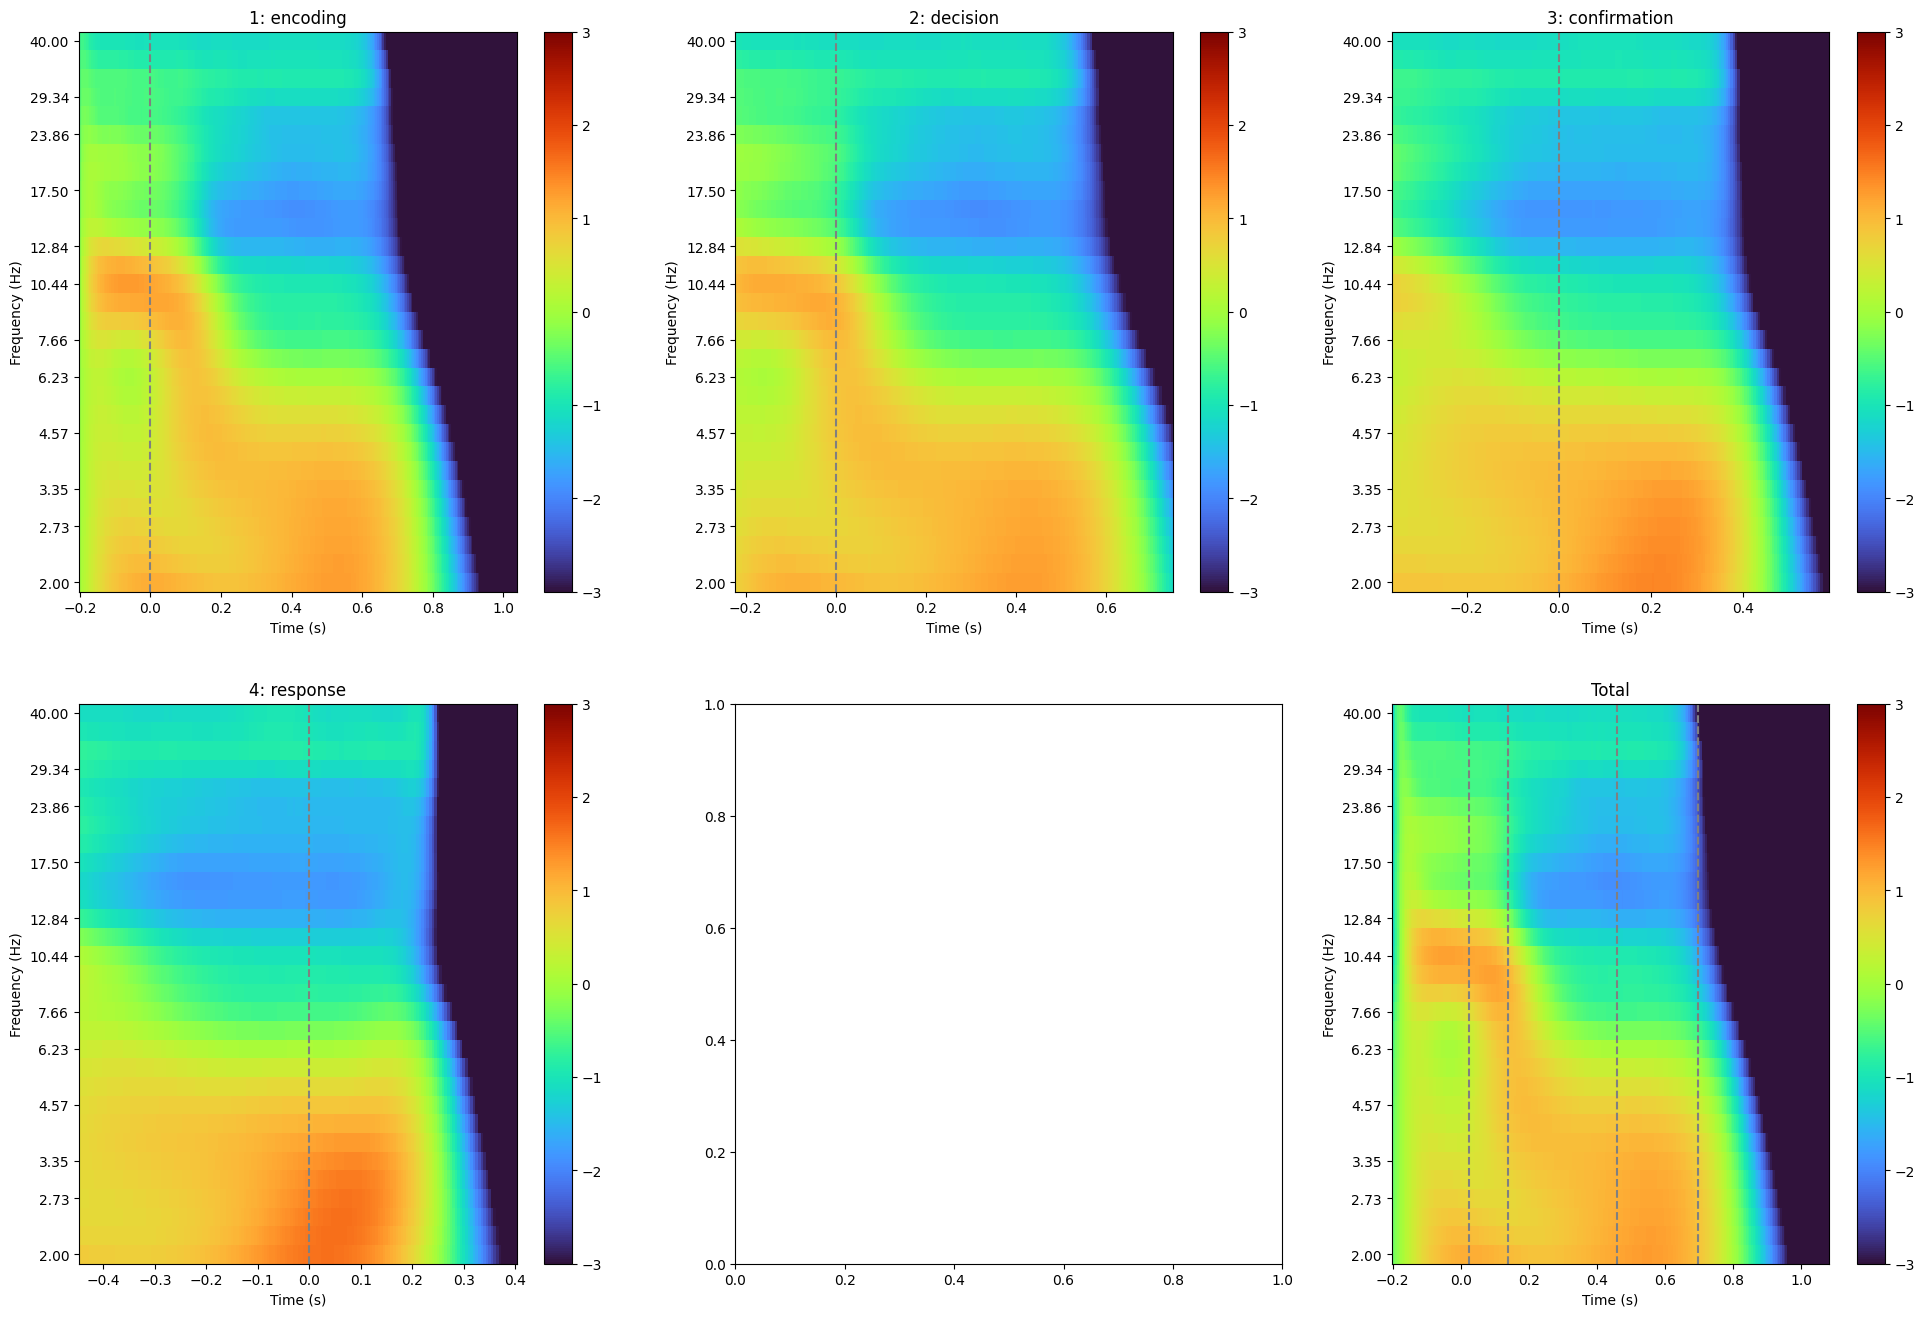

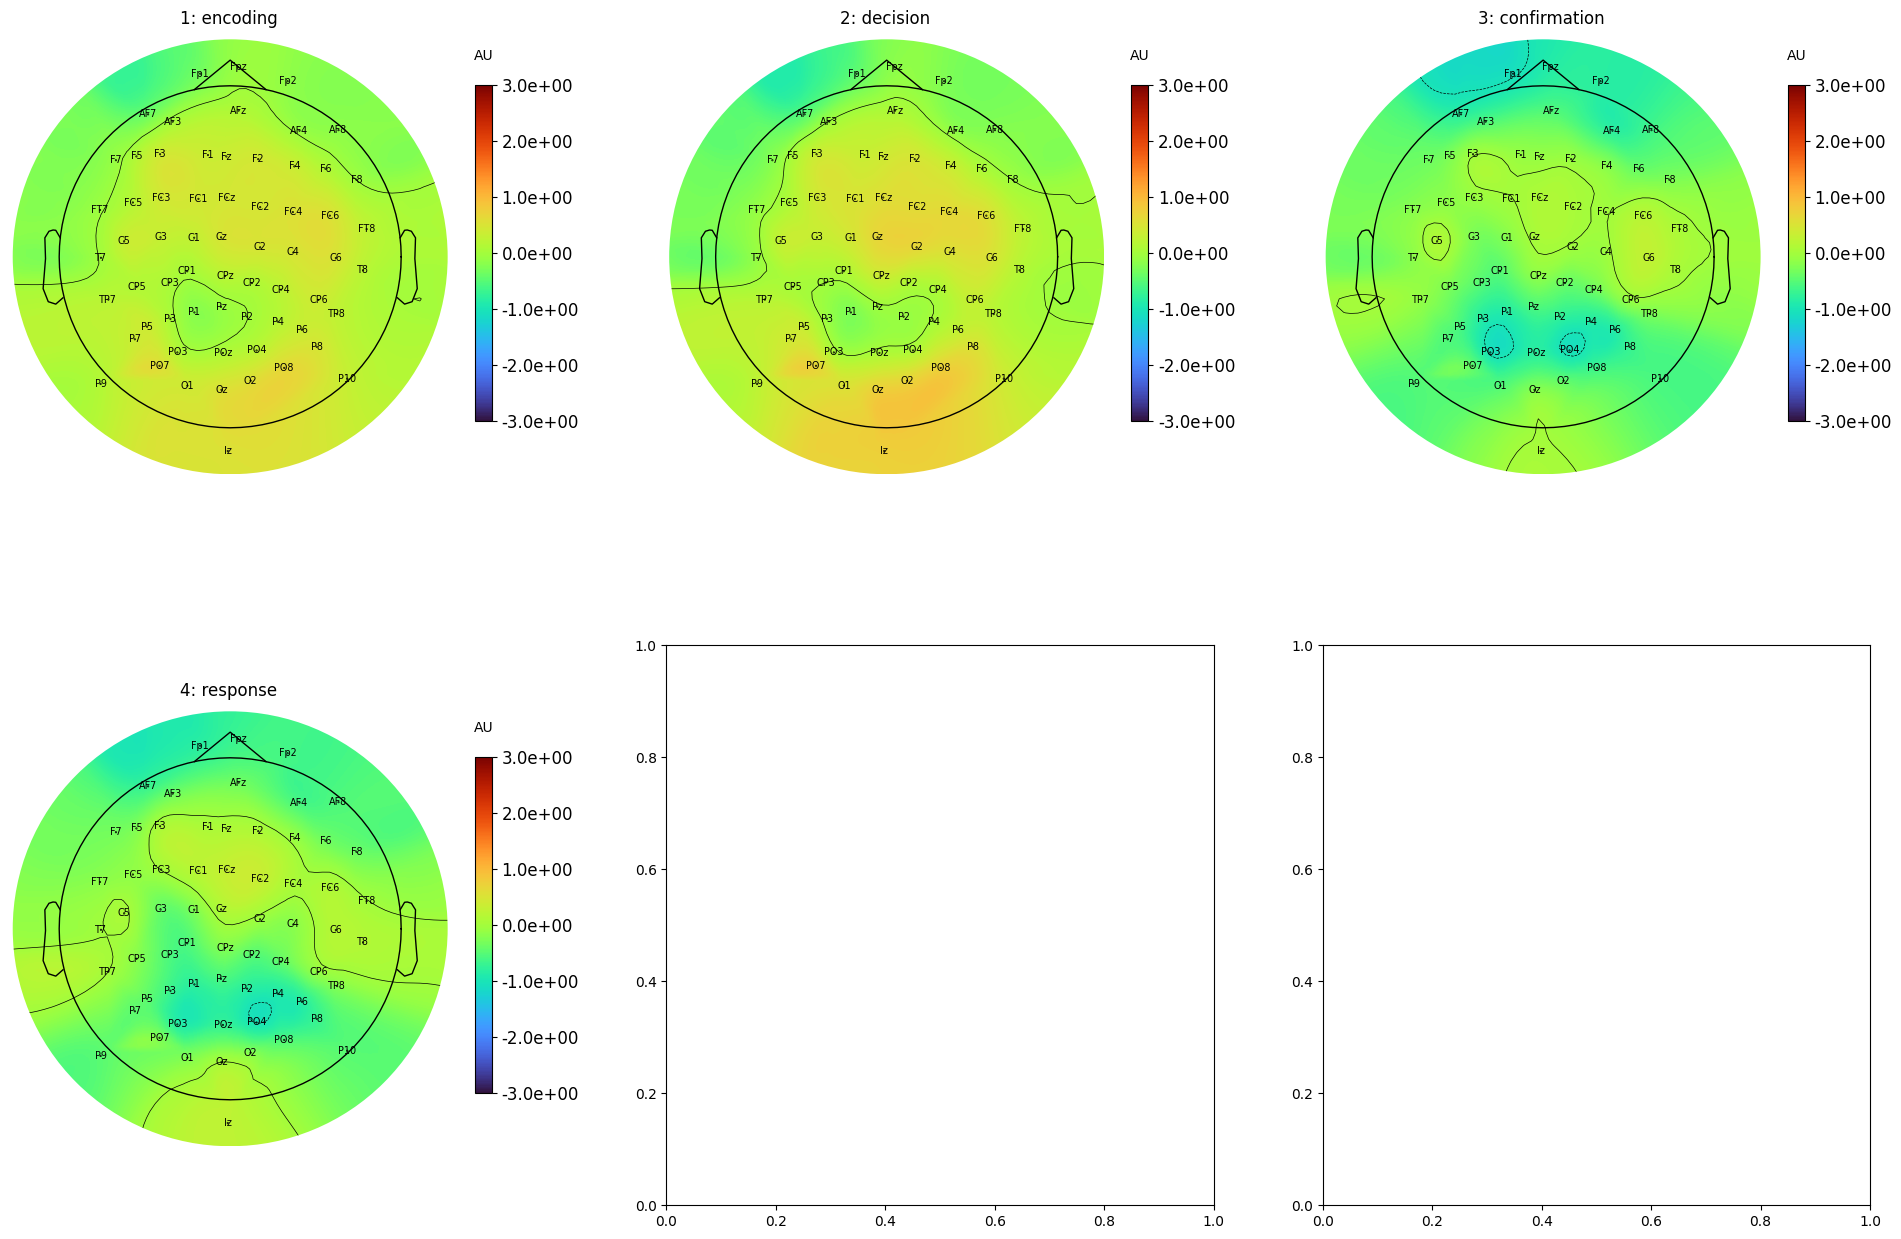

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1[y+1,x].set_xticklabels([((x+lower)-center)/total.sfreq for x in ax1[y+1,x].get_xticks()])
c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1[y+1,x].set_xticklabels([((x+lower)-center)/total.sfreq for x in ax1[y+1,x].get_xticks()])
c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1[y+1,x].set_xticklabels([((x+lower)-center)/total.sfreq for x in ax1[y+1,x].get_xticks()])


No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1[y+1,x].set_xticklabels([((x+lower)-center)/total.sfreq for x in ax1[y+1,x].get_xticks()])


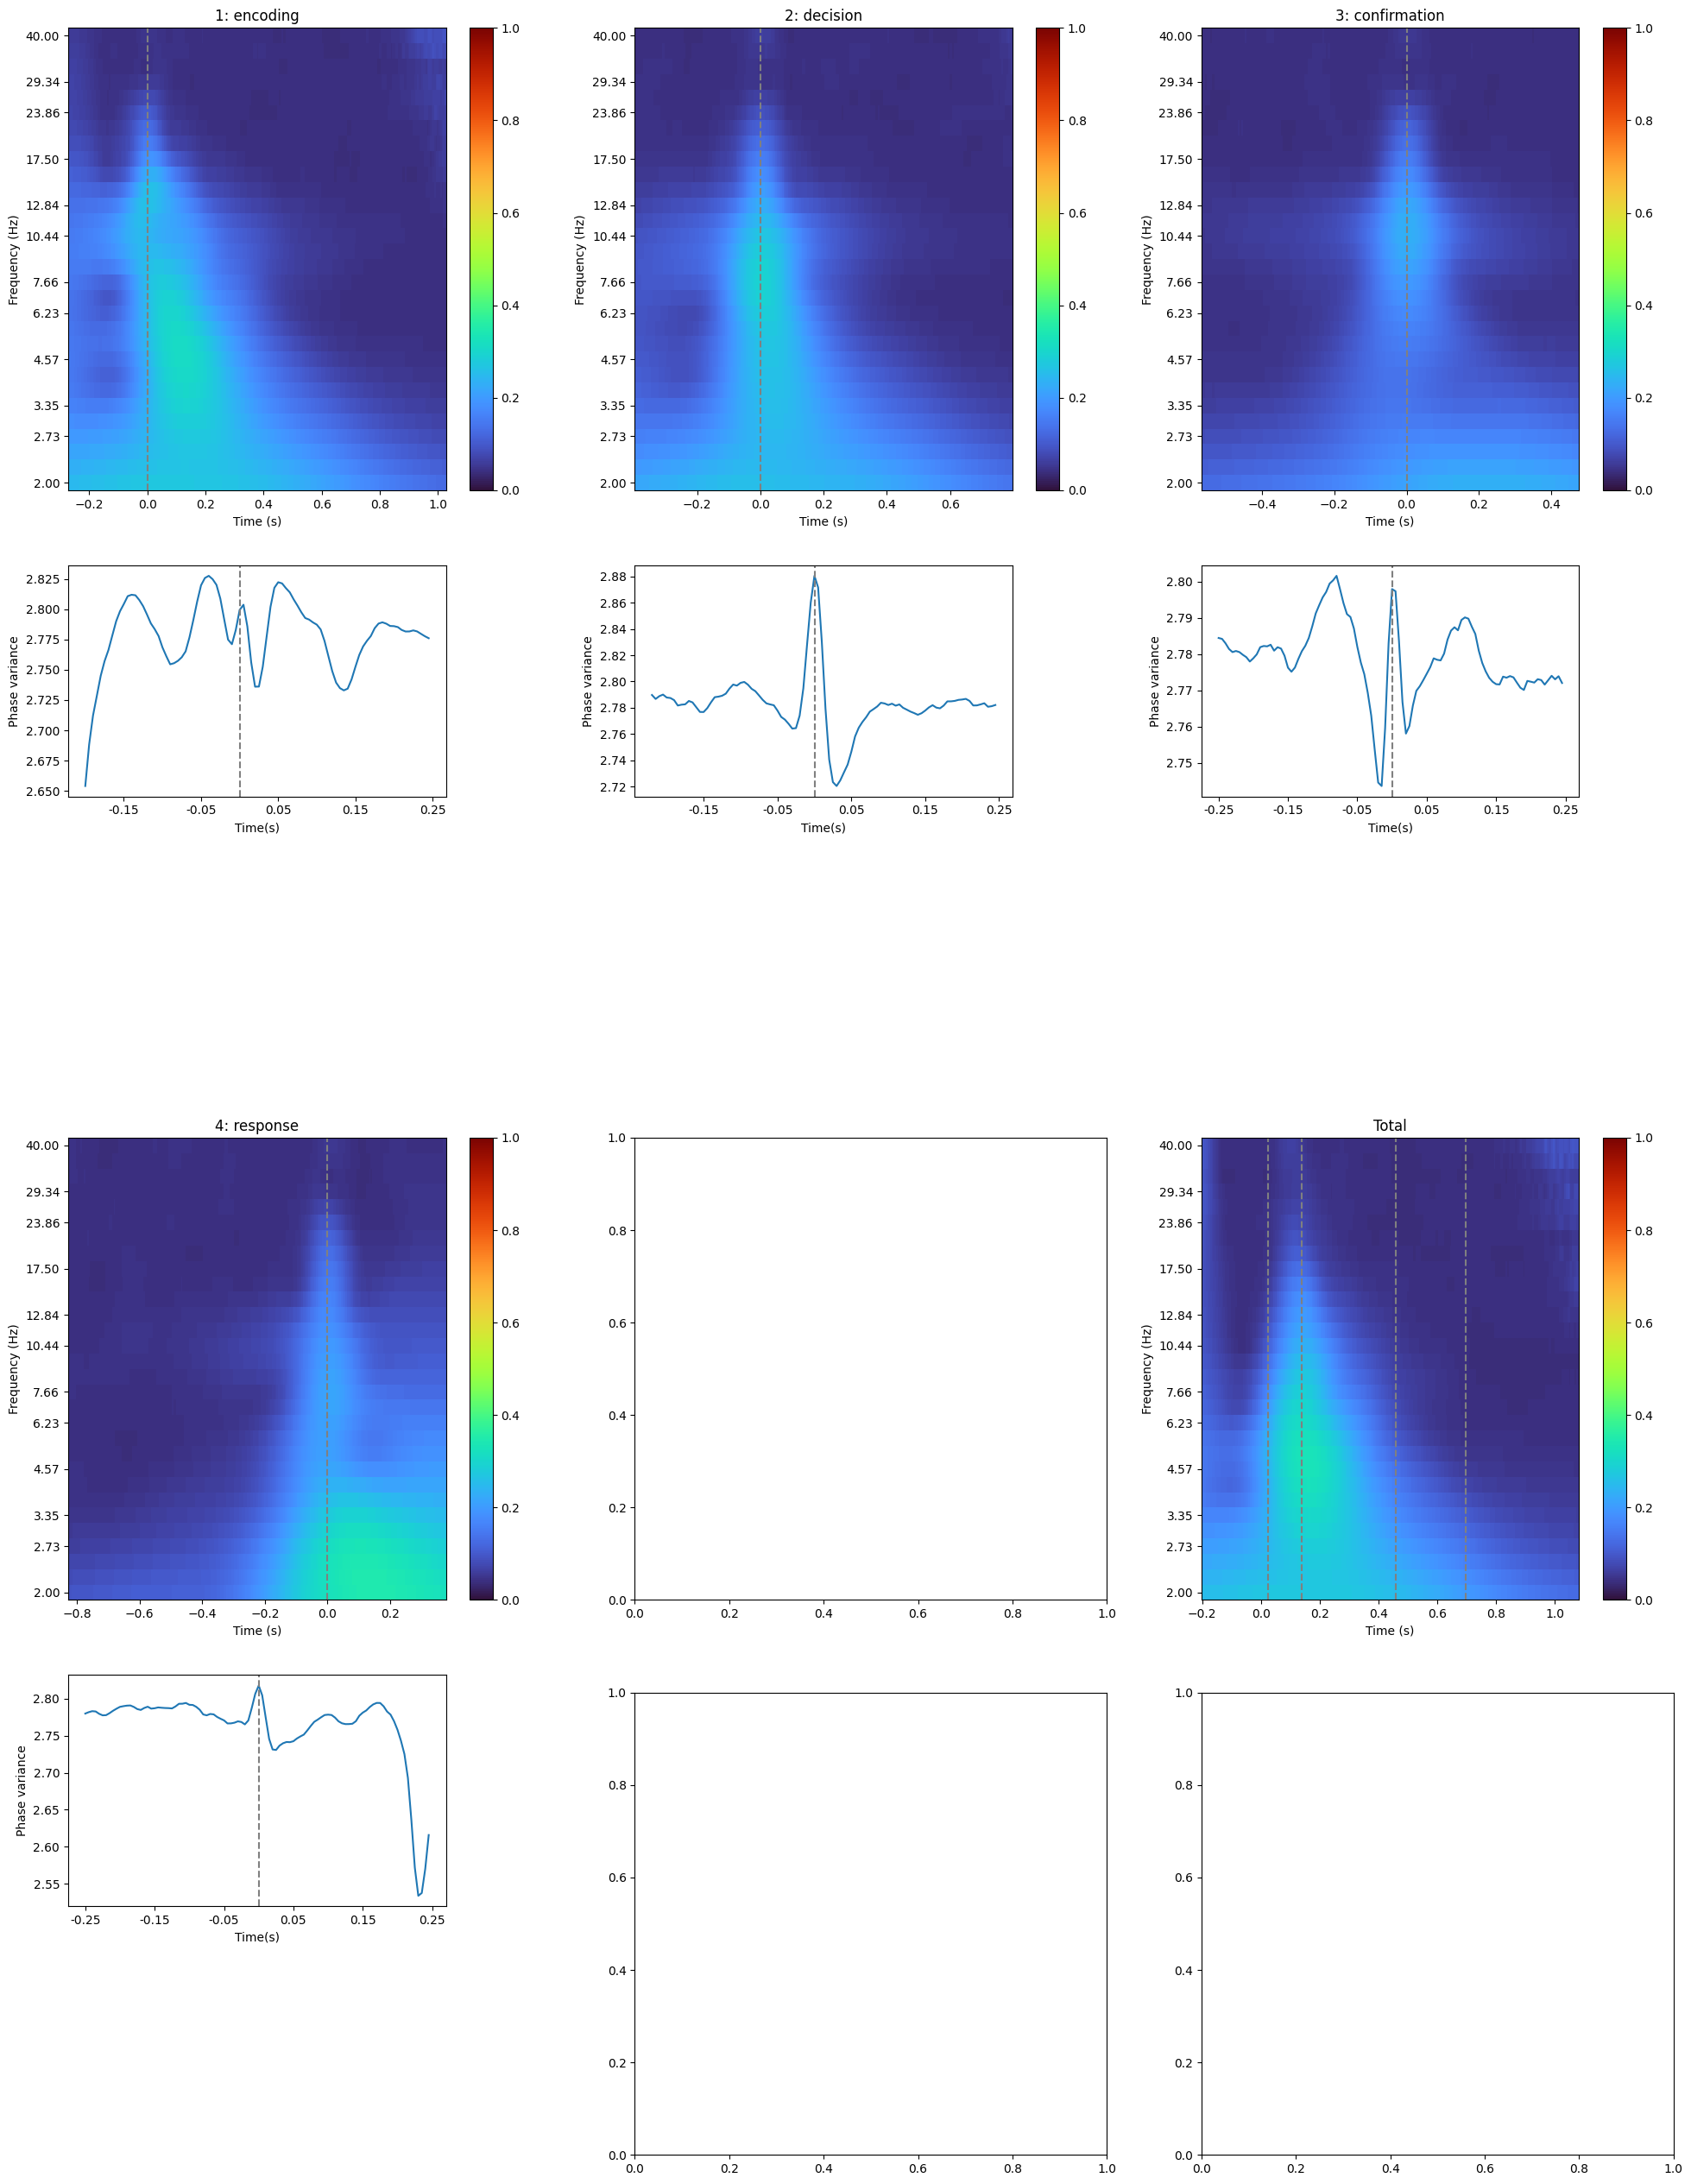

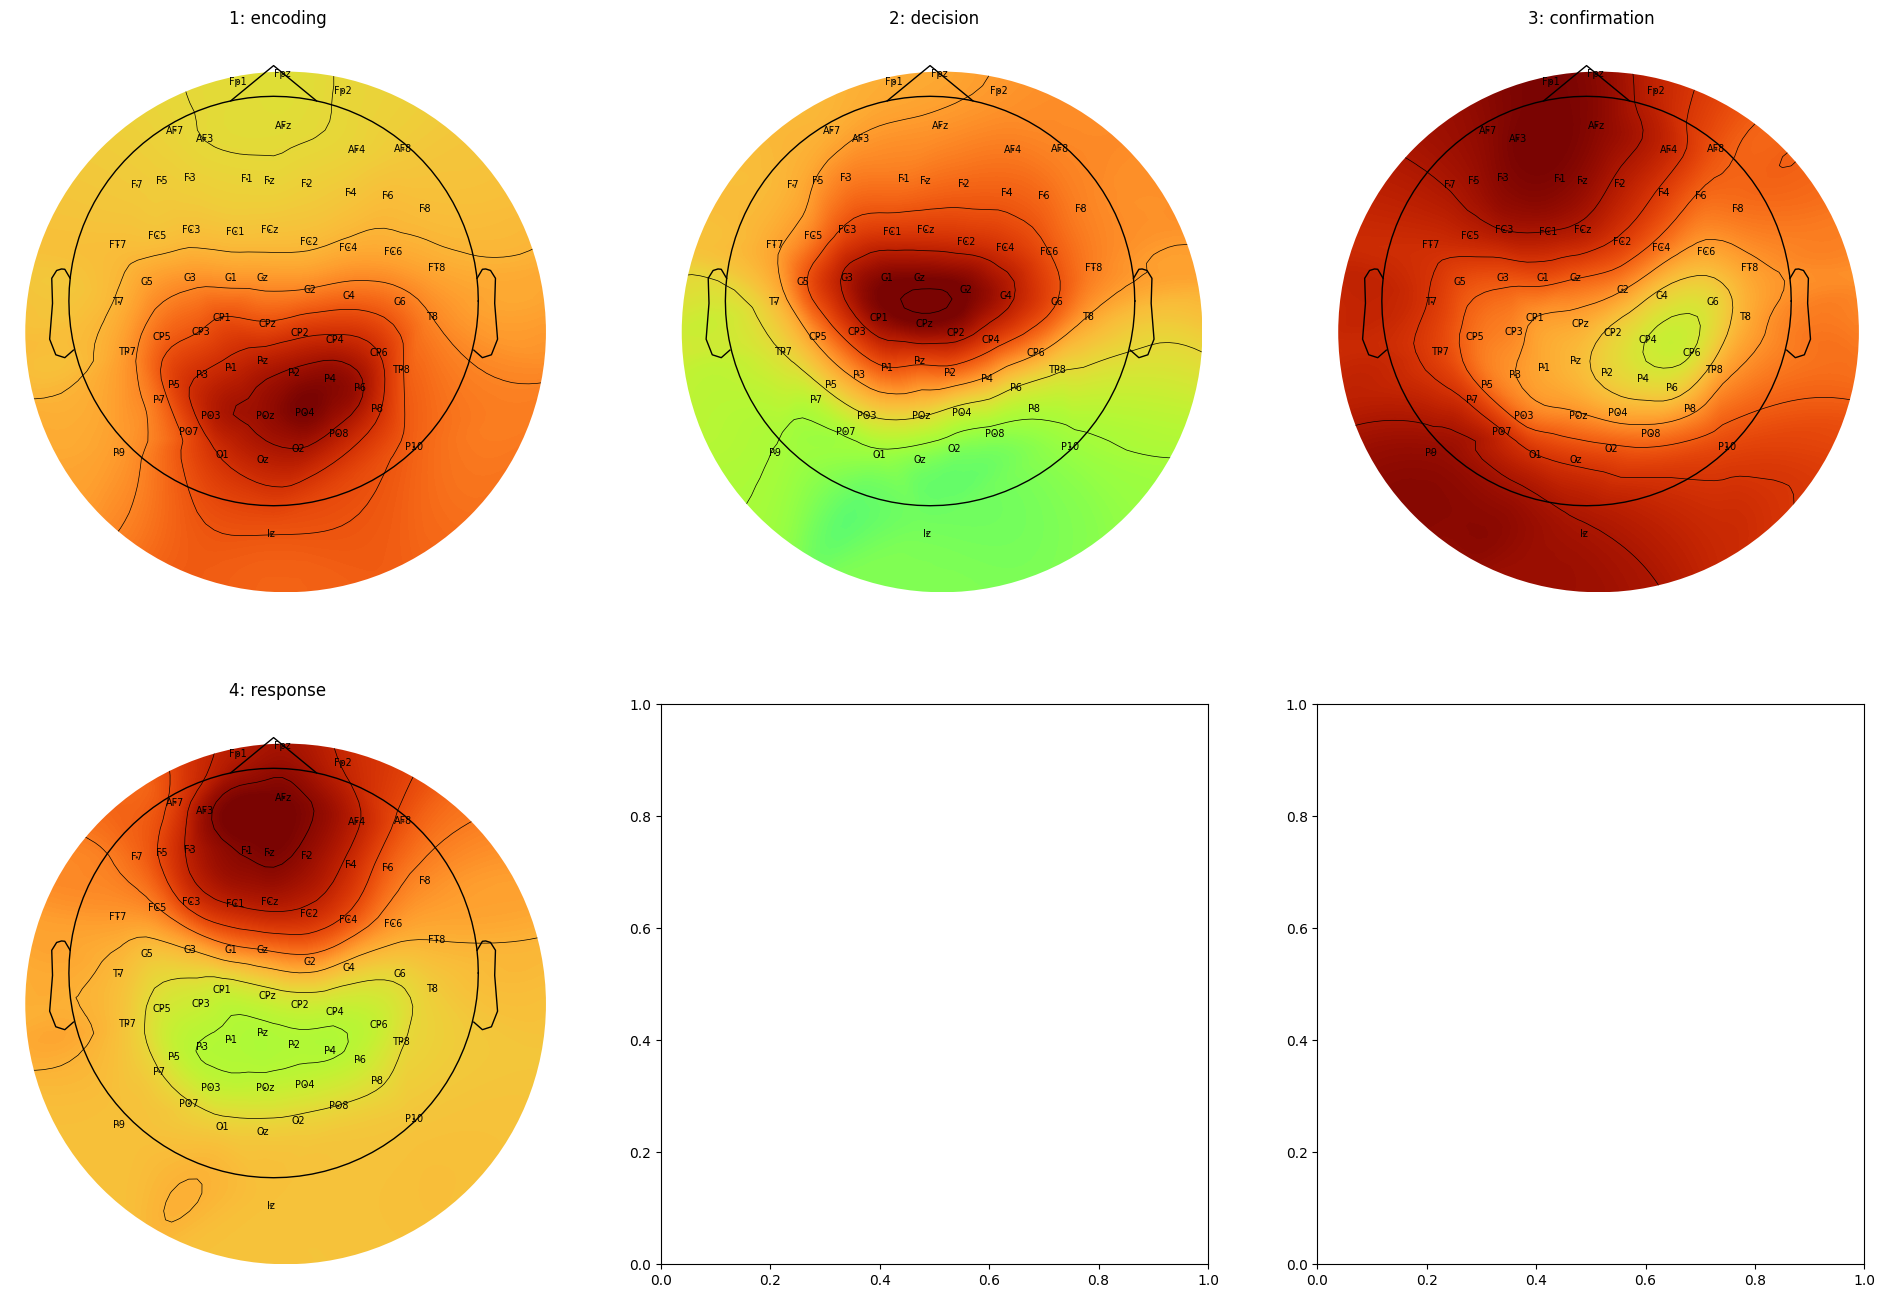

In [14]:
#parameters
channels = 'all'             #list of channels to be plotted. 'all' to plot everything
x_axis = 'adaptive'             #frequency (Hz)

#plot events
AvT.plot_events(tfr_dict, channels, tfr_centers, instance='tfr', x_axis=x_axis)
AvT.plot_events(itc_dict, channels, itc_centers, instance='itc', x_axis=x_axis, phases=phases_dict, vlim=(0,1))